# Predicción del precio de viviendas en Ames, Iowa

## 1. Comprensión del negocio

**Contexto y problema.** El mercado residencial de Ames presenta alta variabilidad estructural y geográfica: dos casas parecidas pueden venderse a precios muy distintos según su tamaño, calidad, antigüedad o ubicación. Cuando agencias y tasadores dependen solo de inspecciones subjetivas, aparecen asimetrías de información: propiedades sobrevaloradas (más días en inventario) o subvaloradas (menor margen comercial). La agencia necesita una forma estándar y automática de valorar propiedades a partir de características objetivas.

**Objetivo.** Construir un modelo de regresión que estime el precio final de venta (`SalePrice`) con el menor error posible, y justificar con evidencia cuál es la mejor solución analítica entre varias alternativas.

**Indicadores de éxito (KPI):**

* **MAE (error absoluto medio):** métrica principal. Expresa en dólares cuánto se desvía en promedio la tasación del precio real, lo que gerencia y corredores entienden de inmediato, y no exagera el efecto de unas pocas casas muy caras.
* **RMSE:** métrica de control de riesgo. Al penalizar más los errores grandes, revela si el modelo falla de forma crítica en algunas viviendas (por ejemplo, las de alto valor).
* **R²:** proporción de la variación del precio que el modelo logra explicar.

**Criterio de decisión.** El modelo se elige por su desempeño en **validación cruzada** (más estable que una sola partición) y se confirma en un conjunto de prueba que no se toca hasta el final.

*Requisitos: las librerías de `requirements.txt` (numpy, pandas, matplotlib, seaborn, scikit-learn, scipy). La ejecución completa toma alrededor de 15 minutos, la mayor parte en la búsqueda de hiperparámetros y el Stacking. Las cifras citadas en el texto corresponden a la ejecución de referencia con semilla 42.*

Dimensiones iniciales: 2,930 registros x 82 variables
Registros duplicados exactos: 0

Top 10 variables con mayor proporción de valores faltantes:
               Nulos  Porcentaje (%)
Pool QC         2917           99.56
Misc Feature    2824           96.38
Alley           2732           93.24
Fence           2358           80.48
Mas Vnr Type    1775           60.58
Fireplace Qu    1422           48.53
Lot Frontage     490           16.72
Garage Qual      159            5.43
Garage Cond      159            5.43
Garage Yr Blt    159            5.43


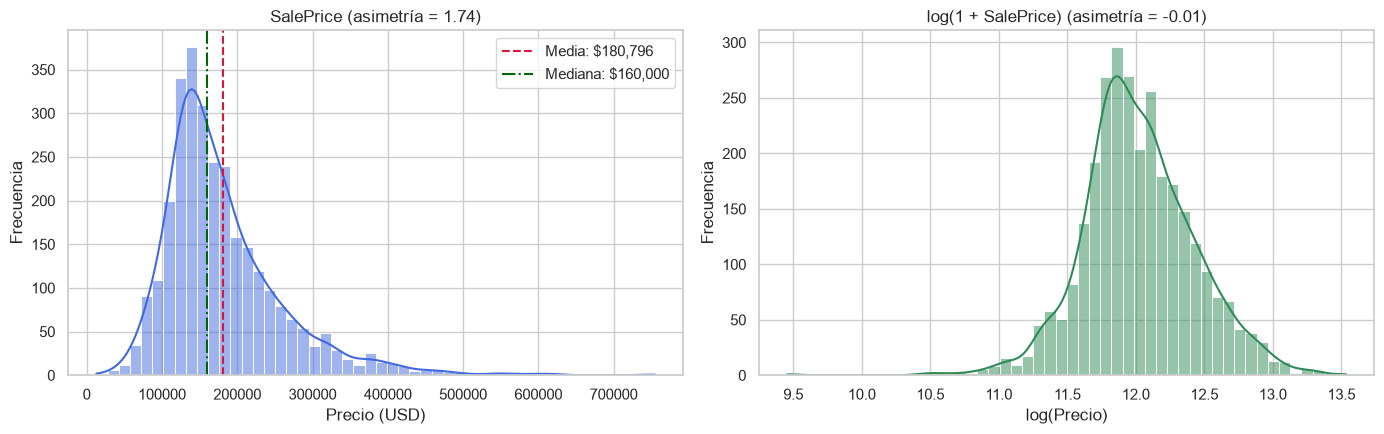

In [1]:
# Importación de librerías y configuración global
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore")  # solo para mantener limpia la salida del notebook
SEED = 42                          # semilla única para que todo sea reproducible

# Carga del dataset (ruta local o de Google Colab)
RUTAS = ["Ames_Iowa_Housing_Dataset.csv", "/content/Ames_Iowa_Housing_Dataset.csv"]
DATA_PATH = next(r for r in RUTAS if os.path.exists(r))
df = pd.read_csv(DATA_PATH)

# 1. Auditoría inicial: tamaño y duplicados
print(f"Dimensiones iniciales: {df.shape[0]:,} registros x {df.shape[1]} variables")
print(f"Registros duplicados exactos: {df.duplicated().sum()}\n")

# 2. Valores faltantes (cantidad y porcentaje)
nulos = df.isnull().sum()
resumen_nulos = (pd.DataFrame({"Nulos": nulos[nulos > 0],
                               "Porcentaje (%)": (nulos[nulos > 0] / len(df) * 100).round(2)})
                 .sort_values("Porcentaje (%)", ascending=False))
print("Top 10 variables con mayor proporción de valores faltantes:")
print(resumen_nulos.head(10))

# 3. Distribución del precio: escala original (con media y mediana) y escala logarítmica
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["SalePrice"], kde=True, bins=50, color="royalblue", ax=ejes[0])
ejes[0].axvline(df["SalePrice"].mean(), color="crimson", linestyle="--",
                label=f"Media: ${df['SalePrice'].mean():,.0f}")
ejes[0].axvline(df["SalePrice"].median(), color="darkgreen", linestyle="-.",
                label=f"Mediana: ${df['SalePrice'].median():,.0f}")
ejes[0].set(title=f"SalePrice (asimetría = {df['SalePrice'].skew():.2f})", xlabel="Precio (USD)",
            ylabel="Frecuencia")
ejes[0].legend()
sns.histplot(np.log1p(df["SalePrice"]), kde=True, bins=50, color="seagreen", ax=ejes[1])
ejes[1].set(title=f"log(1 + SalePrice) (asimetría = {np.log1p(df['SalePrice']).skew():.2f})",
            xlabel="log(Precio)", ylabel="Frecuencia")
plt.tight_layout()
plt.show()

## 2. Exploración y calidad de los datos

**Auditoría inicial.** El dataset tiene 2.930 viviendas y 82 variables, sin registros duplicados. Varias variables tienen muchísimos valores faltantes (piscina, característica especial, callejón, cerca, chimenea). Eso **no es un error de captura**: en este dataset un valor vacío significa que la vivienda *no tiene* esa característica. Por eso más adelante se codifican como la categoría `"None"` en lugar de eliminar las columnas, y así se conserva esa información.

**Variable objetivo.** El precio tiene asimetría positiva: la media (≈ USD 181 mil) queda por encima de la mediana (USD 160 mil) porque unas pocas casas muy caras estiran la cola derecha. El gráfico de la derecha muestra el precio en escala logarítmica, mucho más simétrica. Esto justifica entrenar los modelos sobre `log(1 + precio)`: los errores pasan a ser relativos (un 5 % de error pesa igual en una casa barata que en una cara) y los modelos lineales cumplen mejor sus supuestos. Las predicciones siempre se devuelven a dólares.

### 2.1 Diagnóstico de valores atípicos

Se busca un caso concreto: viviendas de más de 4.000 pies² vendidas por menos de USD 300.000. Es una regla de dominio, no un umbral estadístico arbitrario: en este tipo de dato, una casa tan grande no debería costar tan poco.

Propiedades atípicas detectadas: 3
 Order Neighborhood  Gr Liv Area  Overall Qual Sale Type Sale Condition  SalePrice
  1499      Edwards         5642            10       New        Partial     160000
  2181      Edwards         5095            10       New        Partial     183850
  2182      Edwards         4676            10       New        Partial     184750


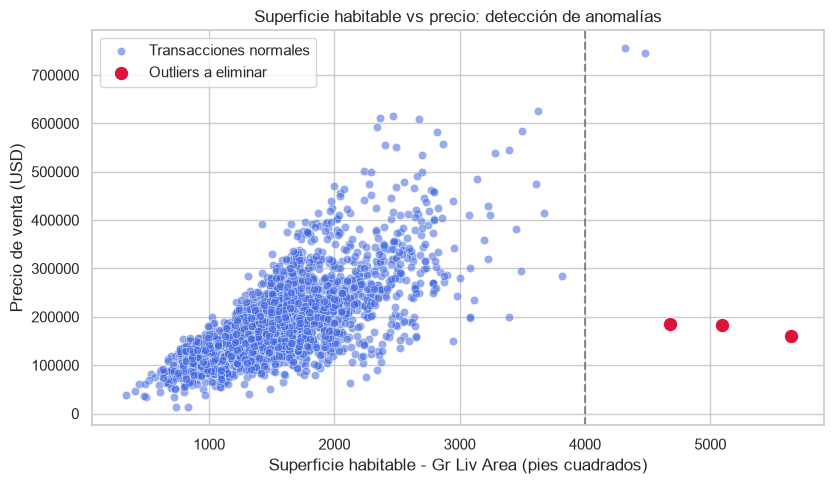

In [2]:
# Detección de outliers estructurales: más de 4.000 pies² y menos de USD 300.000
condicion_outliers = (df["Gr Liv Area"] > 4000) & (df["SalePrice"] < 300000)
outliers_df = df[condicion_outliers]

print(f"Propiedades atípicas detectadas: {len(outliers_df)}")
# Sale Condition permite verificar el tipo de transacción de cada caso
print(outliers_df[["Order", "Neighborhood", "Gr Liv Area", "Overall Qual",
                   "Sale Type", "Sale Condition", "SalePrice"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice", color="royalblue", alpha=0.55,
                ax=ax, label="Transacciones normales")
sns.scatterplot(data=outliers_df, x="Gr Liv Area", y="SalePrice", color="crimson", s=110,
                ax=ax, label="Outliers a eliminar")
ax.axvline(x=4000, color="dimgray", linestyle="--", alpha=0.75)
ax.set(title="Superficie habitable vs precio: detección de anomalías",
       xlabel="Superficie habitable - Gr Liv Area (pies cuadrados)", ylabel="Precio de venta (USD)")
ax.legend()
plt.tight_layout()
plt.show()

**Resultado.** Se detectan 3 propiedades y comparten un patrón: están en el mismo vecindario (Edwards), son obra nueva (`Sale Type = New`), tienen calidad 10 y su `Sale Condition` es `Partial`, es decir, ventas parciales, típicas de viviendas aún no terminadas al momento de la tasación. Su precio (USD 160 mil a 185 mil) no refleja el valor de una casa de 4.700 a 5.600 pies² y de calidad máxima. Son transacciones no representativas del mercado abierto y, al ser pocas pero muy influyentes, distorsionarían los modelos (en especial los lineales). Las dos viviendas de más de 4.000 pies² vendidas por USD 745 mil a 755 mil sí son coherentes con el mercado y se conservan.

### 2.2 Limpieza y correlación

**Decisiones de limpieza:**

* **Outliers:** se eliminan las 3 ventas atípicas. Se hace antes de dividir los datos porque es una decisión de calidad de datos y no un parámetro aprendido desde el conjunto de prueba.
* **Valores faltantes:** se tratan **dentro del `Pipeline`** del modelado (sección 4), no aquí. Las categóricas faltantes se rellenan con la constante `"None"` y las numéricas con la mediana *calculada solo sobre el entrenamiento de cada fold*. Si las medianas se calcularan con todo el dataset antes de dividir, la información del conjunto de prueba se filtraría al entrenamiento (**fuga de datos**) y las métricas saldrían más optimistas de lo real.

**Correlación.** Se calcula la correlación de Pearson con el precio solo para explorar. Los impulsores principales son la calidad general (r ≈ 0,80), la superficie habitable (r ≈ 0,73) y la superficie de sótano, la capacidad de garaje y el año de construcción. El mapa de calor muestra además que varias de estas variables están muy correlacionadas entre sí (por ejemplo, `Garage Cars` y `Garage Area`): esa multicolinealidad es una razón para probar modelos regularizados. Pearson mide solo relaciones lineales, así que no se usa para descartar variables; todos los modelos reciben todas las columnas.

Dataset depurado: 2,927 filas x 82 columnas (precio medio $180,801, mediana $160,000)

Top 10 variables numéricas con mayor correlación lineal con SalePrice:
Overall Qual      0.803
Gr Liv Area       0.727
Total Bsmt SF     0.661
Garage Cars       0.648
1st Flr SF        0.646
Garage Area       0.644
Year Built        0.559
Full Bath         0.546
Year Remod/Add    0.533
Garage Yr Blt     0.527
Name: SalePrice, dtype: float64


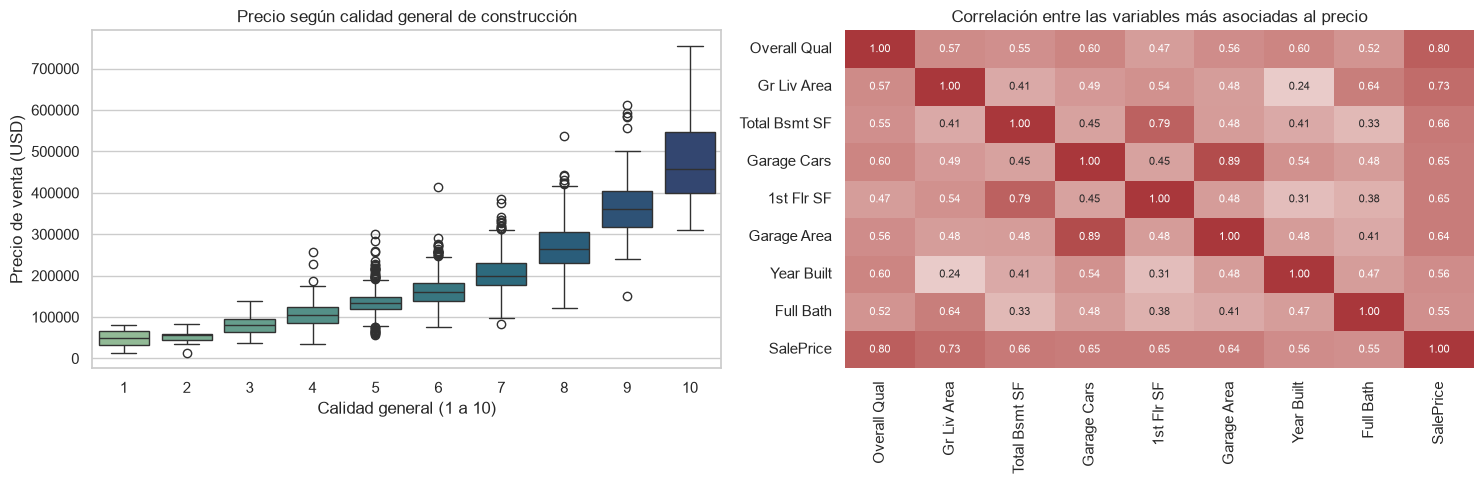

In [3]:
# Eliminación de outliers. Se hace antes de dividir los datos porque es una decisión de calidad
# de datos (ventas no representativas), no un parámetro aprendido desde el conjunto de prueba.
df = df.drop(index=outliers_df.index).reset_index(drop=True)
print(f"Dataset depurado: {df.shape[0]:,} filas x {df.shape[1]} columnas "
      f"(precio medio ${df['SalePrice'].mean():,.0f}, mediana ${df['SalePrice'].median():,.0f})")

# Correlación de Pearson con el precio (solo exploratoria: no alimenta al modelo supervisado)
correlaciones = (df.select_dtypes(include=np.number).corr()["SalePrice"]
                   .drop("SalePrice").sort_values(ascending=False))
print("\nTop 10 variables numéricas con mayor correlación lineal con SalePrice:")
print(correlaciones.head(10).round(3))

# Panel: precio por calidad general (boxplot) y correlaciones entre las 8 variables más asociadas
top8 = correlaciones.head(8).index.tolist() + ["SalePrice"]
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="Overall Qual", y="SalePrice", palette="crest", ax=ejes[0])
ejes[0].set(title="Precio según calidad general de construcción",
            xlabel="Calidad general (1 a 10)", ylabel="Precio de venta (USD)")
sns.heatmap(df[top8].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, cbar=False,
            annot_kws={"size": 8}, ax=ejes[1])
ejes[1].set_title("Correlación entre las variables más asociadas al precio")
plt.tight_layout()
plt.show()

## 3. Aprendizaje no supervisado: segmentación de propiedades

Antes de predecir precios individuales se agrupan las viviendas por tipología con **K-Means**, sin usar el precio.

**Variables elegidas.** `Overall Qual`, `Gr Liv Area` y `Year Built`, según la correlación anterior. Son las tres dimensiones físicas más representativas (calidad, tamaño y antigüedad), fáciles de explicar al negocio. Se **excluye el precio** para que los segmentos describan *tipos de vivienda* y no simples rangos de precio.

**Escalado.** K-Means agrupa por distancia euclidiana. Sin escalar, los pies cuadrados (cientos o miles) dominarían sobre la calidad (1 a 10) y el año. `StandardScaler` deja las tres variables con media 0 y desviación 1, con el mismo peso.

**Elección de K.** Se usan dos criterios: la inercia (método del codo) y el coeficiente de silueta, que mide qué tan separados están los grupos (más alto es mejor).

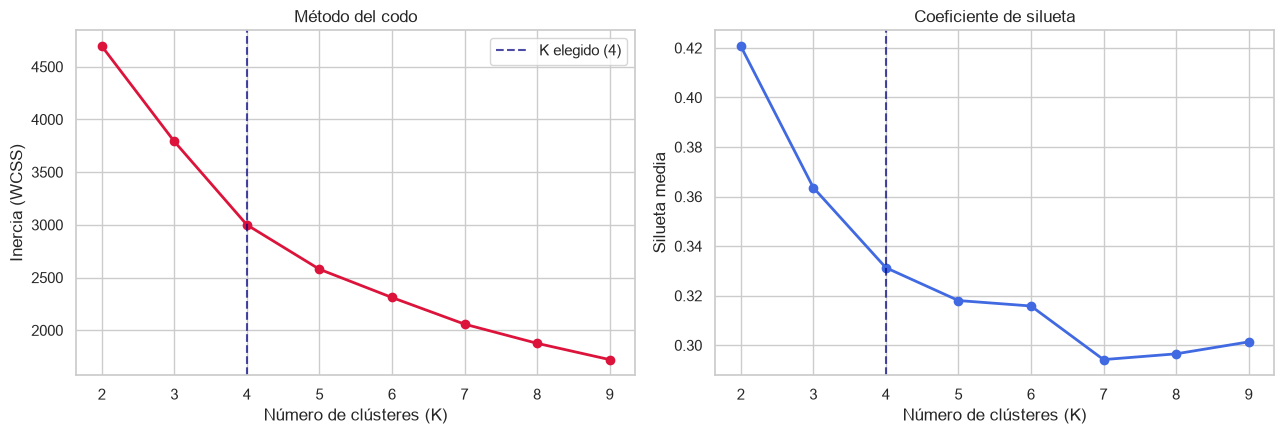

{2: 0.421, 3: 0.364, 4: 0.331, 5: 0.318, 6: 0.316, 7: 0.294, 8: 0.297, 9: 0.301}


In [6]:
# Segmentación: K-Means sobre 3 variables estructurales (sin el precio)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

features_kmeans = ["Overall Qual", "Gr Liv Area", "Year Built"]
X_scaled = StandardScaler().fit_transform(df[features_kmeans])  # misma escala para todas

# Para cada K se guarda la inercia (método del codo) y el coeficiente de silueta
rango_k = range(2, 10)
inercias, siluetas = [], []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(X_scaled)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_scaled, km.labels_))

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].plot(rango_k, inercias, marker="o", color="crimson", linewidth=2)
ejes[0].axvline(4, color="navy", linestyle="--", alpha=0.7, label="K elegido (4)")
ejes[0].set(title="Método del codo", xlabel="Número de clústeres (K)", ylabel="Inercia (WCSS)")
ejes[0].legend()
ejes[1].plot(rango_k, siluetas, marker="o", color="royalblue", linewidth=2)
ejes[1].axvline(4, color="navy", linestyle="--", alpha=0.7)
ejes[1].set(title="Coeficiente de silueta", xlabel="Número de clústeres (K)", ylabel="Silueta media")
plt.tight_layout()
plt.show()
print({k: round(s, 3) for k, s in zip(rango_k, siluetas)})

### 3.1 Perfilamiento comercial de los segmentos (K = 4)

**Por qué K = 4.** Los criterios no coinciden del todo. La inercia deja de caer tan rápido a partir de K = 4 (la pendiente se suaviza), aunque no hay un codo tajante. La silueta es máxima con K = 2 (≈ 0,42) y baja gradualmente hasta ≈ 0,33 con K = 4. Con solo 2 grupos la segmentación separa "casas chicas" de "casas grandes" y es demasiado gruesa para recomendar propiedades similares. K = 4 mantiene una silueta moderada (estructura real, aunque con grupos que se solapan) y entrega perfiles bien distinguibles. Es una **decisión de negocio apoyada en métricas**, no un óptimo matemático.

**Perfiles obtenidos** (nombre comercial asignado según el precio medio del segmento):

* **Premium contemporáneo** (422 viviendas, ≈ USD 316 mil): amplias (≈ 2.270 pies²), modernas (1997) y de calidad 8.
* **Moderno estándar** (917, ≈ USD 199 mil): recientes (1997), tamaño intermedio (≈ 1.500 pies²) y buena calidad.
* **Histórico amplio** (528, ≈ USD 152 mil): casas antiguas (1933) con metraje generoso (≈ 1.710 pies²) y calidad intermedia, candidatas habituales a remodelación.
* **Económico compacto** (1.060, ≈ USD 125 mil): menor superficie (≈ 1.080 pies²), antigüedad media (1958) y calidad básica.

Aunque el precio no se usó para agrupar, los segmentos quedan ordenados por precio: capturan factores reales de valor. La segmentación **no** se usa como variable del modelo supervisado; se reutiliza al final para analizar en qué tipo de vivienda se equivoca más el modelo.

Perfil promedio de cada segmento:


,,Viviendas,Calidad,Superficie,Año,Precio_medio
Cluster,Segmento,,,,,
3,Premium contemporáneo,422,8.0,2267.0,1997.0,315516.0
0,Moderno estándar,917,6.8,1501.0,1997.0,199308.0
2,Histórico amplio,528,5.6,1709.0,1933.0,152160.0
1,Económico compacto,1060,4.9,1079.0,1958.0,125425.0


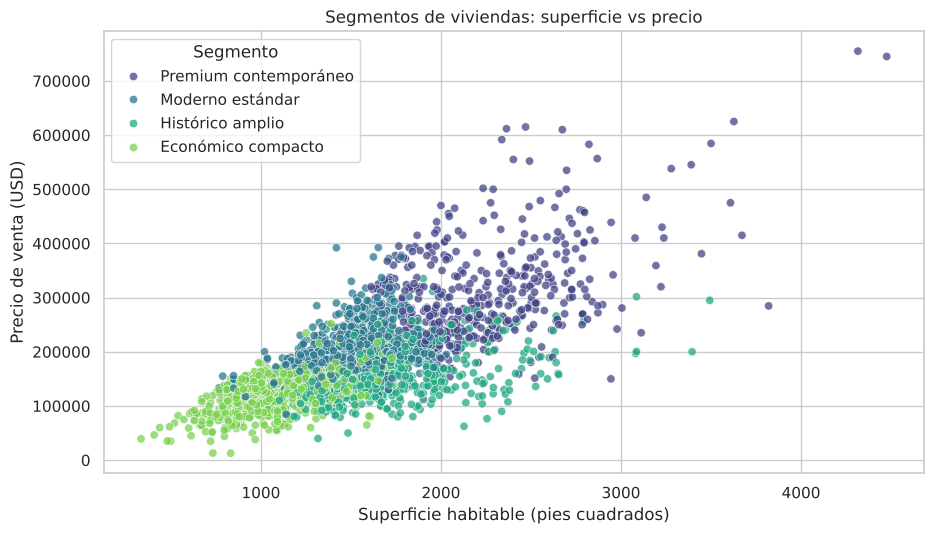

In [ ]:
# Modelo final de segmentación y perfilamiento comercial de cada clúster
K_FINAL = 4
df["Cluster"] = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10).fit_predict(X_scaled)

# Nombre comercial asignado según el precio medio del clúster (de menor a mayor)
orden_precio = df.groupby("Cluster")["SalePrice"].mean().sort_values().index
nombres = ["Económico compacto", "Histórico amplio", "Moderno estándar", "Premium contemporáneo"]
mapa_nombres = dict(zip(orden_precio, nombres))
df["Segmento"] = df["Cluster"].map(mapa_nombres)

perfil = (df.groupby(["Cluster", "Segmento"])
            .agg(Viviendas=("SalePrice", "size"), Calidad=("Overall Qual", "mean"),
                 Superficie=("Gr Liv Area", "mean"), Año=("Year Built", "mean"),
                 Precio_medio=("SalePrice", "mean"))
            .round({"Calidad": 1, "Superficie": 0, "Año": 0, "Precio_medio": 0})
            .sort_values("Precio_medio", ascending=False))
print("Perfil promedio de cada segmento:")
display(perfil)

fig, ax = plt.subplots(figsize=(9.5, 5.5))
sns.scatterplot(data=df, x="Gr Liv Area", y="SalePrice", hue="Segmento",
                hue_order=nombres[::-1], palette="viridis", alpha=0.75, ax=ax)
ax.set(title="Segmentos de viviendas: superficie vs precio",
       xlabel="Superficie habitable (pies cuadrados)", ylabel="Precio de venta (USD)")
plt.tight_layout()
plt.show()

## 4. Aprendizaje supervisado: diseño del experimento

Esta sección fija las reglas para que la comparación entre modelos sea justa y creíble.

* **Partición 80/20.** El 20 % de prueba (586 casas) se separa ahora y solo se usa al final. Todo el ajuste (comparar modelos, optimizar hiperparámetros) se hace con el 80 % restante (2.341 casas). Se excluyen los identificadores (`Order`, `PID`) y las columnas derivadas de la segmentación.
* **Pipeline.** Imputación, codificación one-hot y modelo van en un solo objeto. En cada fold de la validación cruzada el preprocesamiento aprende solo de los datos de entrenamiento de ese fold, evitando la fuga de datos.
* **One-hot con `min_frequency=5`.** Las categorías con menos de 5 casas se agrupan, lo que evita columnas casi vacías que solo añaden ruido. `handle_unknown="ignore"` evita errores si en producción aparece una categoría nueva.
* **Escalado solo para modelos lineales.** Los árboles no lo necesitan; la regresión lineal y Ridge sí, para que la regularización trate igual a todas las variables.
* **Objetivo en `log(1 + precio)`**, por lo explicado en la sección 2.
* **Validación cruzada de 5 folds**, con los mismos folds para todos los modelos. Con 2.341 casas una sola partición da una estimación ruidosa; la CV promedia cinco y entrega la desviación entre folds (estabilidad). Además se registra el **MAE de entrenamiento** de cada fold: la distancia entre el error de entrenamiento y el de validación sirve para diagnosticar sobreajuste.

### 4.1 Línea base

Antes de optimizar se mide cada modelo con su configuración por defecto:

* **Regresión lineal y Ridge** (lineal con regularización L2): Ridge penaliza coeficientes grandes, lo que ayuda con las columnas correlacionadas que genera el one-hot. Su parámetro `alpha` se elige por validación interna (`RidgeCV`).
* **Random Forest** (ensamble por *bagging*): promedia muchos árboles independientes entrenados sobre muestras *bootstrap*, lo que reduce la **varianza**.
* **Gradient Boosting e HistGradientBoosting** (ensambles por *boosting*): construyen árboles poco profundos en secuencia, cada uno corrigiendo los errores del anterior, lo que reduce el **sesgo** y captura relaciones no lineales e interacciones.

In [ ]:
# Preparación del modelado supervisado
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y = df["SalePrice"]
# Se excluyen el objetivo, identificadores y las columnas derivadas de la segmentación
X = df.drop(columns=["SalePrice", "PID", "Order", "Cluster", "Segmento"])
cols_num = X.select_dtypes(include=np.number).columns.tolist()
cols_cat = X.select_dtypes(exclude=np.number).columns.tolist()
print(f"{len(cols_num)} variables numéricas y {len(cols_cat)} categóricas")

# El 20% de prueba se separa ahora y no se vuelve a tocar hasta la evaluación final
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")


def crear_preprocesador(escalar=False):
    """Imputa y codifica dentro del Pipeline, de modo que cada fold de la validación cruzada
    aprende sus propias medianas y categorías (evita fuga de datos)."""
    pasos_num = [("imputador", SimpleImputer(strategy="median"))]
    if escalar:  # solo los modelos lineales lo necesitan; los árboles no
        pasos_num.append(("escalador", StandardScaler()))
    pasos_cat = [
        ("imputador", SimpleImputer(strategy="constant", fill_value="None")),  # NaN = "no tiene"
        ("codificador", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False)),
    ]
    return ColumnTransformer([("num", Pipeline(pasos_num), cols_num),
                              ("cat", Pipeline(pasos_cat), cols_cat)])


def crear_modelo(estimador, escalar=False):
    """Pipeline completo. El objetivo se entrena en log(1+precio) y se devuelve a dólares."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", crear_preprocesador(escalar)), ("modelo", estimador)]),
        func=np.log1p, inverse_func=np.expm1)


# Validación cruzada de 5 folds, la misma para todos los modelos (comparación justa)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}


def evaluar_cv(nombre, modelo):
    """Métricas medias de la validación cruzada. Incluye el MAE en los folds de entrenamiento:
    la diferencia con el MAE de validación sirve para diagnosticar sobreajuste."""
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=METRICAS,
                       return_train_score=True, n_jobs=-1)
    return {"Modelo": nombre,
            "MAE_train": -r["train_mae"].mean(),
            "MAE_CV": -r["test_mae"].mean(), "MAE_std": r["test_mae"].std(),
            "RMSE_CV": -r["test_rmse"].mean(), "R2_CV": r["test_r2"].mean()}

36 variables numéricas y 43 categóricas
Entrenamiento: (2341, 79) | Prueba: (586, 79)


In [ ]:
# Línea base: modelos con configuración por defecto, evaluados con validación cruzada
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

ALPHAS_RIDGE = np.logspace(-1, 3, 20)
modelos_base = {
    "Regresión Lineal":              crear_modelo(LinearRegression(), escalar=True),
    "Ridge":                         crear_modelo(RidgeCV(alphas=ALPHAS_RIDGE), escalar=True),
    "Random Forest (defecto)":       crear_modelo(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1)),
    "Gradient Boosting (defecto)":   crear_modelo(GradientBoostingRegressor(random_state=SEED)),
    "HistGradientBoosting (defecto)": crear_modelo(HistGradientBoostingRegressor(random_state=SEED)),
}
tabla_base = pd.DataFrame([evaluar_cv(n, m) for n, m in modelos_base.items()]).set_index("Modelo")
tabla_base["Brecha (CV - train)"] = tabla_base["MAE_CV"] - tabla_base["MAE_train"]
print("Línea base (validación cruzada de 5 folds sobre el 80% de entrenamiento):")
display(tabla_base.sort_values("MAE_CV").round(3))

Línea base (validación cruzada de 5 folds sobre el 80% de entrenamiento):


,MAE_train,MAE_CV,MAE_std,RMSE_CV,R2_CV,Brecha (CV - train)
Modelo,,,,,,
Ridge,12378.046,13691.982,701.486,20736.408,0.926,1313.936
Regresión Lineal,11879.258,14189.361,818.632,21599.686,0.920,2310.103
HistGradientBoosting (defecto),5752.512,14523.508,879.281,22990.254,0.911,8770.996
Gradient Boosting (defecto),10792.518,14539.966,649.087,22349.786,0.915,3747.447
Random Forest (defecto),6019.793,16190.901,862.966,25824.834,0.888,10171.108


**Lectura de la línea base** (MAE en validación cruzada, ejecución de referencia): Ridge ≈ USD 13.692, Regresión Lineal ≈ 14.189, HistGradientBoosting ≈ 14.524, Gradient Boosting ≈ 14.540 y Random Forest ≈ 16.191.

* **Regularizar ayuda a los modelos lineales:** Ridge mejora a la regresión lineal sin regularizar (−3,5 %) y tiene menor dispersión entre folds.
* **Sobreajuste en los árboles por defecto:** Random Forest logra un MAE de entrenamiento de ≈ USD 6.020 contra ≈ 16.191 en validación (brecha ≈ 10.171); HistGradientBoosting tiene una brecha de ≈ 8.771. Los modelos lineales tienen brechas mucho menores (1.314 y 2.310). Los árboles con valores por defecto son demasiado flexibles y memorizan parte del ruido.
* **Los modelos por defecto no están ajustados a este problema**, así que esta comparación aún no dice cuál es mejor. La siguiente sección mide cuánto mejoran al optimizarlos.

## 5. Optimización de hiperparámetros

**Estrategia: búsqueda aleatoria (`RandomizedSearchCV`) con validación cruzada.** Se prefiere sobre una grilla porque, con 5 o 6 hiperparámetros, la grilla crece de forma explosiva y gasta la mayor parte del tiempo en combinaciones poco útiles. La búsqueda aleatoria explora más valores distintos de cada hiperparámetro con el mismo presupuesto, y permite usar distribuciones continuas (por ejemplo, la tasa de aprendizaje en escala logarítmica).

**Decisiones de diseño:**

* **Métrica de optimización: MAE**, la misma del KPI de negocio, para que "mejor modelo" signifique lo mismo en todo el proyecto.
* **Misma CV de 5 folds** que la línea base, de modo que la mejora sea comparable.
* **Espacios de búsqueda acotados y con sentido:**
  * *Gradient Boosting:* `learning_rate` baja con `n_estimators` alto (aprender despacio suele generalizar mejor), `max_depth` entre 2 y 4 (aprendices débiles), `subsample` y `max_features` menores a 1 (añaden aleatoriedad que reduce el sobreajuste) y `min_samples_leaf` para evitar hojas con muy pocas casas.
  * *HistGradientBoosting:* además, `l2_regularization` y `max_leaf_nodes` controlan la complejidad.
  * *Random Forest:* `max_depth`, `min_samples_leaf` y `max_features` (con menos variables por árbol, los árboles se parecen menos entre sí y el promedio mejora).
* **Presupuesto:** 12, 20 y 10 combinaciones respectivamente. Es un límite práctico de tiempo; un presupuesto mayor podría mejorar algo más los resultados.

In [ ]:
# Optimización de hiperparámetros con búsqueda aleatoria + validación cruzada.
# Los nombres "regressor__modelo__x" apuntan al hiperparámetro x dentro del Pipeline.
from scipy.stats import randint, uniform, loguniform

def optimizar(estimador, espacio, n_iter):
    """Búsqueda aleatoria sobre MAE (la métrica de negocio) con la misma CV de la línea base."""
    busqueda = RandomizedSearchCV(
        crear_modelo(estimador),
        {f"regressor__modelo__{k}": v for k, v in espacio.items()},
        n_iter=n_iter, cv=cv, scoring="neg_mean_absolute_error",
        random_state=SEED, n_jobs=-1)
    return busqueda.fit(X_train, y_train)

espacios = {
    "gbr": (GradientBoostingRegressor(random_state=SEED), 12, {
        "n_estimators": randint(300, 600), "learning_rate": loguniform(0.02, 0.1),
        "max_depth": randint(2, 5), "subsample": uniform(0.6, 0.4),
        "min_samples_leaf": randint(3, 20), "max_features": uniform(0.2, 0.5)}),
    "hgb": (HistGradientBoostingRegressor(random_state=SEED), 20, {
        "learning_rate": loguniform(0.02, 0.15), "max_iter": randint(200, 600),
        "max_leaf_nodes": randint(8, 40), "min_samples_leaf": randint(5, 40),
        "l2_regularization": loguniform(1e-3, 10)}),
    "rf": (RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1), 10, {
        "max_depth": randint(8, 30), "min_samples_leaf": randint(1, 6),
        "max_features": uniform(0.15, 0.4)}),
}

busquedas = {}
for nombre, (est, n_iter, espacio) in espacios.items():
    t0 = time.time()
    busquedas[nombre] = optimizar(est, espacio, n_iter)
    print(f"{nombre.upper()}: MAE CV = ${-busquedas[nombre].best_score_:,.0f} ({time.time() - t0:.0f} s)")
    print({k.split("__")[-1]: (round(v.item(), 4) if hasattr(v, "item") else v)
           for k, v in busquedas[nombre].best_params_.items()}, "\n")

# Comparación antes/después de optimizar
comparacion = pd.DataFrame({
    "MAE defecto": [tabla_base.loc["Gradient Boosting (defecto)", "MAE_CV"],
                    tabla_base.loc["HistGradientBoosting (defecto)", "MAE_CV"],
                    tabla_base.loc["Random Forest (defecto)", "MAE_CV"]],
    "MAE optimizado": [-busquedas[k].best_score_ for k in ["gbr", "hgb", "rf"]]},
    index=["Gradient Boosting", "HistGradientBoosting", "Random Forest"])
comparacion["Mejora %"] = (1 - comparacion["MAE optimizado"] / comparacion["MAE defecto"]) * 100
display(comparacion.round(1))

GBR: MAE CV = $13,497 (100 s)
{'learning_rate': 0.041, 'max_depth': 4, 'max_features': 0.229, 'min_samples_leaf': 6, 'n_estimators': 451, 'subsample': 0.8604} 

HGB: MAE CV = $13,829 (299 s)
{'l2_regularization': 2.7527, 'learning_rate': 0.0788, 'max_iter': 528, 'max_leaf_nodes': 14, 'min_samples_leaf': 22} 

RF: MAE CV = $15,488 (55 s)
{'max_depth': 24, 'max_features': 0.3599, 'min_samples_leaf': 2} 



,MAE defecto,MAE optimizado,Mejora %
Gradient Boosting,14540.0,13496.7,7.2
HistGradientBoosting,14523.5,13829.4,4.8
Random Forest,16190.9,15487.5,4.3


**Resultados de la optimización** (MAE en CV, ejecución de referencia):

| Modelo | Defecto | Optimizado | Mejora |
|---|---|---|---|
| Gradient Boosting | ≈ 14.540 | ≈ 13.497 | 7,2 % |
| HistGradientBoosting | ≈ 14.524 | ≈ 13.829 | 4,8 % |
| Random Forest | ≈ 16.191 | ≈ 15.488 | 4,3 % |

La optimización mejora a los tres modelos, más a los de *boosting*, que tienen más hiperparámetros sensibles. Los valores elegidos apuntan en la dirección esperada: aprendizaje lento, árboles poco profundos y submuestreo de filas y columnas, es decir, regularización. El Gradient Boosting optimizado pasa a ser el mejor modelo individual de árboles y supera a Ridge. Random Forest sigue siendo el más débil: con más de 200 columnas tras el one-hot, muchas poco informativas, el *boosting* aprovecha mejor las variables importantes.

## 6. Técnicas de ensamble

Los modelos individuales cometen errores distintos: Ridge captura bien las relaciones lineales, y los árboles capturan no linealidades e interacciones. Un ensamble aprovecha esa **diversidad**. Se prueban dos técnicas con los mismos cuatro modelos base (Ridge, Random Forest, Gradient Boosting e HistGradientBoosting, los tres últimos ya optimizados):

* **Voting (promedio):** promedia las predicciones con el mismo peso. Es simple, rápido y difícil de sobreajustar, pero trata igual a un modelo bueno y a uno regular.
* **Stacking (apilamiento):** un meta-modelo (Ridge) aprende **cuánto peso dar a cada modelo base**. Para que esos pesos no se aprendan con predicciones demasiado buenas sobre datos ya vistos, el meta-modelo se entrena con predicciones *fuera de muestra* generadas por validación cruzada interna (`cv=5`). Es más costoso, pero suele ser más preciso.

La pregunta clave es si el ensamble realmente mejora respecto de sus componentes. Se responde en la siguiente sección con las mismas métricas y los mismos folds.

In [ ]:
# Técnicas de ensamble: se combinan los mejores modelos optimizados con un lineal regularizado
from sklearn.base import clone
from sklearn.ensemble import VotingRegressor, StackingRegressor

# Pipelines sin entrenar, ya con los mejores hiperparámetros
def pipeline_optimo(clave):
    return clone(busquedas[clave].best_estimator_.regressor)

pipe_ridge = Pipeline([("prep", crear_preprocesador(True)), ("modelo", RidgeCV(alphas=ALPHAS_RIDGE))])
base_ensamble = [("ridge", pipe_ridge), ("rf", pipeline_optimo("rf")),
                 ("gbr", pipeline_optimo("gbr")), ("hgb", pipeline_optimo("hgb"))]

# Voting: promedio simple de las predicciones
voting = VotingRegressor(base_ensamble)
# Stacking: un Ridge aprende cuánto pesar cada modelo base usando predicciones fuera de muestra (cv=5)
stacking = StackingRegressor(base_ensamble, final_estimator=RidgeCV(alphas=np.logspace(-2, 2, 10)), cv=5)

modelos_finales = {
    "Regresión Lineal":            modelos_base["Regresión Lineal"],
    "Ridge":                       crear_modelo(RidgeCV(alphas=ALPHAS_RIDGE), escalar=True),
    "Random Forest (opt.)":        busquedas["rf"].best_estimator_,
    "Gradient Boosting (opt.)":    busquedas["gbr"].best_estimator_,
    "HistGradientBoosting (opt.)": busquedas["hgb"].best_estimator_,
    "Voting":                      TransformedTargetRegressor(regressor=voting, func=np.log1p, inverse_func=np.expm1),
    "Stacking":                    TransformedTargetRegressor(regressor=stacking, func=np.log1p, inverse_func=np.expm1),
}

## 7. Evaluación de la capacidad de generalización

Generalizar es predecir bien casas que el modelo **no vio**. Se evalúa en tres niveles:

1. **Entrenamiento vs validación (CV):** la brecha entre el MAE de entrenamiento y el de validación mide cuánto "memoriza" el modelo.
2. **Validación cruzada (5 folds):** entrega el MAE promedio y su **desviación entre folds**. Una desviación baja indica que el modelo rinde parecido sin importar qué casas le toquen.
3. **Conjunto de prueba (20 %):** se usa una única vez, con modelos ya entrenados. Si el error de prueba fuera mucho mayor que el de CV, sería señal de sobreajuste.

Métricas: MAE, RMSE y R², por lo explicado en la sección 1.

Regresión Lineal: listo (1 s)
Ridge: listo (1 s)
Random Forest (opt.): listo (8 s)
Gradient Boosting (opt.): listo (8 s)
HistGradientBoosting (opt.): listo (14 s)
Voting: listo (34 s)
Stacking: listo (173 s)


,MAE_train,MAE_CV,MAE_std,RMSE_CV,R2_CV,MAE_test,RMSE_test,R2_test,Brecha (CV - train),Brecha (test - CV),Error relativo test (%)
Modelo,,,,,,,,,,,
Stacking,9179.622,12840.568,580.727,19432.308,0.936,11364.488,16499.833,0.966,3660.946,-1476.080,6.210
Voting,7140.943,13078.648,563.957,20467.628,0.929,11938.926,18711.317,0.957,5937.704,-1139.722,6.523
Gradient Boosting (opt.),7715.551,13496.721,607.402,21065.551,0.925,12172.601,18825.306,0.956,5781.170,-1324.120,6.651
Ridge,12378.046,13691.982,701.486,20736.408,0.926,12555.945,18147.463,0.959,1313.936,-1136.038,6.861
HistGradientBoosting (opt.),4484.350,13829.380,661.006,22026.392,0.919,13531.072,22001.578,0.940,9345.030,-298.309,7.393
Regresión Lineal,11879.258,14189.361,818.632,21599.686,0.920,12830.555,18542.031,0.957,2310.103,-1358.806,7.011
Random Forest (opt.),6856.026,15487.525,723.189,25004.534,0.895,14574.905,24872.140,0.923,8631.500,-912.621,7.964


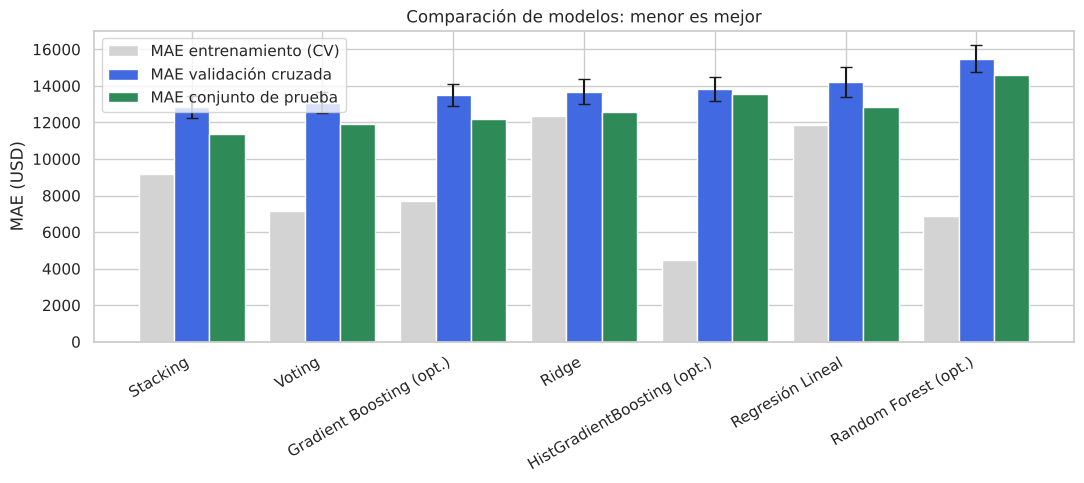

In [ ]:
# Evaluación de generalización: validación cruzada (train y validación) y conjunto de prueba
filas, pred_test, entrenados = [], {}, {}
for nombre, modelo in modelos_finales.items():
    t0 = time.time()
    fila = evaluar_cv(nombre, clone(modelo))             # CV con una copia sin entrenar
    entrenados[nombre] = clone(modelo).fit(X_train, y_train)
    pred_test[nombre] = entrenados[nombre].predict(X_test)
    fila.update({"MAE_test": mean_absolute_error(y_test, pred_test[nombre]),
                 "RMSE_test": np.sqrt(mean_squared_error(y_test, pred_test[nombre])),
                 "R2_test": r2_score(y_test, pred_test[nombre])})
    filas.append(fila)
    print(f"{nombre}: listo ({time.time() - t0:.0f} s)")

resultados = pd.DataFrame(filas).set_index("Modelo").sort_values("MAE_CV")
resultados["Brecha (CV - train)"] = resultados["MAE_CV"] - resultados["MAE_train"]
resultados["Brecha (test - CV)"] = resultados["MAE_test"] - resultados["MAE_CV"]
resultados["Error relativo test (%)"] = resultados["MAE_test"] / y_test.mean() * 100
display(resultados.round(3))

# Gráfico: MAE de entrenamiento, validación cruzada (con desviación entre folds) y prueba
orden = resultados.index
pos = np.arange(len(orden))
plt.figure(figsize=(11, 5))
plt.bar(pos - 0.27, resultados["MAE_train"], 0.27, label="MAE entrenamiento (CV)", color="lightgray")
plt.bar(pos, resultados["MAE_CV"], 0.27, yerr=resultados["MAE_std"], capsize=4,
        label="MAE validación cruzada", color="royalblue")
plt.bar(pos + 0.27, resultados["MAE_test"], 0.27, label="MAE conjunto de prueba", color="seagreen")
plt.xticks(pos, orden, rotation=30, ha="right")
plt.ylabel("MAE (USD)")
plt.title("Comparación de modelos: menor es mejor")
plt.legend()
plt.tight_layout()
plt.show()

**Lectura de los resultados** (ejecución de referencia, MAE en USD):

| Modelo | MAE entrenamiento | MAE CV | MAE prueba |
|---|---|---|---|
| **Stacking** | ≈ 9.180 | **≈ 12.841** (± 581) | **≈ 11.364** |
| Voting | ≈ 7.141 | ≈ 13.079 | ≈ 11.939 |
| Gradient Boosting (opt.) | ≈ 7.716 | ≈ 13.497 | ≈ 12.173 |
| Ridge | ≈ 12.378 | ≈ 13.692 | ≈ 12.556 |
| HistGradientBoosting (opt.) | ≈ 4.484 | ≈ 13.829 | ≈ 13.531 |
| Regresión Lineal | ≈ 11.879 | ≈ 14.189 | ≈ 12.831 |
| Random Forest (opt.) | ≈ 6.856 | ≈ 15.488 | ≈ 14.575 |

* **Aporte del ensamble:** Stacking reduce el MAE en CV un 4,9 % frente al mejor modelo individual (Gradient Boosting) y un 9,5 % frente a la regresión lineal. Voting también mejora a sus componentes, pero menos: aprender los pesos aporta más que promediar.
* **Brecha entrenamiento–validación:** los modelos de árboles tienen brechas grandes (por ejemplo, ≈ 9.345 en HistGradientBoosting), mientras que Ridge tiene una pequeña (≈ 1.314). Una brecha grande es típica de los árboles, que se ajustan mucho al entrenamiento, y no es en sí un problema: lo que importa es el error sobre datos no vistos, y ahí los árboles optimizados y los ensambles superan a los lineales. (El MAE de entrenamiento del Stacking no es estrictamente comparable porque sus modelos base se reentrenan con todo el conjunto.)
* **Generalización:** en **todos** los modelos el error de prueba es *menor* que el de CV. No hay señales de sobreajuste hacia datos nuevos. La diferencia se explica en parte porque en CV cada modelo se entrena con el 80 % del entrenamiento (menos datos) y en parte por azar: este conjunto de prueba resultó algo más fácil. El orden de los modelos es prácticamente el mismo en CV y en prueba, lo que da confianza en la comparación.
* **Estabilidad:** la desviación entre folds del Stacking (≈ 581) es similar a la de los demás modelos (la menor es la del Voting, ≈ 564), por lo que la mejora no viene de un fold afortunado.
* **Precaución:** con una sola partición de prueba (586 casas), diferencias de unos pocos cientos de dólares entre modelos cercanos (por ejemplo, Stacking y Voting) no deben sobreinterpretarse. La ventaja del Stacking se sostiene porque es consistente en CV y en prueba.

## 8. Selección y justificación de la solución analítica óptima

La selección se hace por **MAE en validación cruzada** (criterio fijado en la sección 1), no por el resultado de prueba, para no elegir "mirando el examen". Luego se diagnostica el modelo elegido de tres formas:

* **Real vs predicho:** los puntos deben seguir la diagonal.
* **Residuos vs predicho:** no deben mostrar patrón; un abanico o una curva indicarían errores sistemáticos.
* **Error por segmento (clústeres):** muestra en qué tipo de vivienda falla más, algo que un promedio global esconde.

Modelo seleccionado: Stacking
MAE de prueba: $11,364 (6.2% del precio medio)
Reducción del MAE vs regresión lineal simple: 11.4%


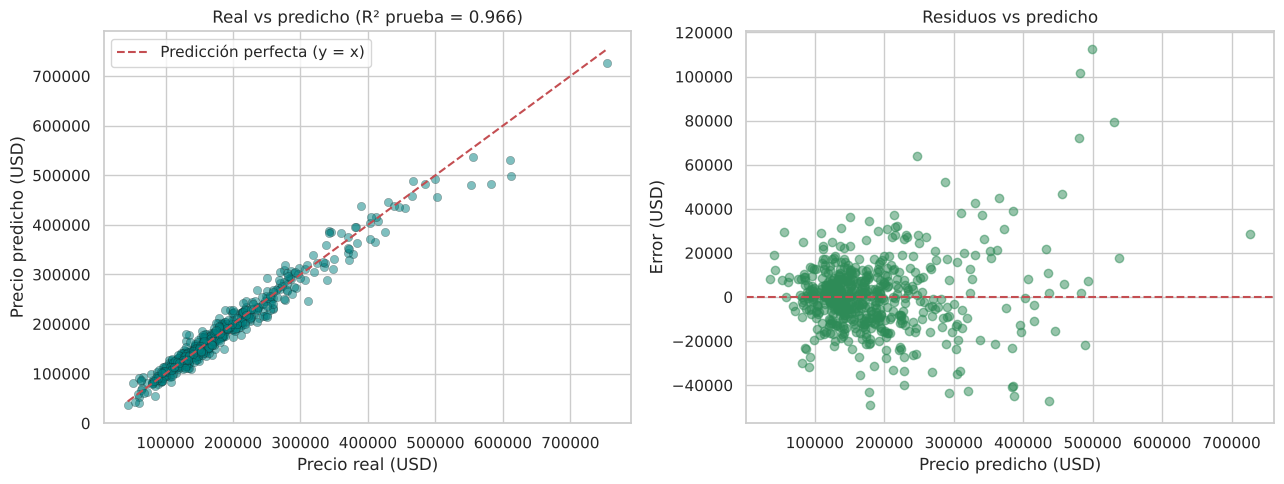

,Viviendas,MAE,Precio_medio,MAE %
Segmento,,,,
Económico compacto,220,8163.9,126706.5,6.4
Histórico amplio,111,10860.3,150554.5,7.2
Moderno estándar,175,10802.0,197801.7,5.5
Premium contemporáneo,80,22096.2,350567.8,6.3


In [ ]:
# Diagnóstico del modelo seleccionado (el de menor MAE en validación cruzada)
elegido = resultados.index[0]
modelo_elegido = entrenados[elegido]
pred = pred_test[elegido]
error = y_test - pred
print(f"Modelo seleccionado: {elegido}")
print(f"MAE de prueba: ${mean_absolute_error(y_test, pred):,.0f} "
      f"({mean_absolute_error(y_test, pred) / y_test.mean():.1%} del precio medio)")
mae_lineal = resultados.loc["Regresión Lineal", "MAE_test"]
print(f"Reducción del MAE vs regresión lineal simple: {1 - resultados.loc[elegido, 'MAE_test'] / mae_lineal:.1%}")

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
ejes[0].scatter(y_test, pred, alpha=0.5, color="teal", edgecolors="k", linewidth=0.3)
lim = [y_test.min(), y_test.max()]
ejes[0].plot(lim, lim, "r--", label="Predicción perfecta (y = x)")
ejes[0].set(title=f"Real vs predicho (R² prueba = {r2_score(y_test, pred):.3f})",
            xlabel="Precio real (USD)", ylabel="Precio predicho (USD)")
ejes[0].legend()
ejes[1].scatter(pred, error, alpha=0.5, color="seagreen")
ejes[1].axhline(0, color="r", linestyle="--")
ejes[1].set(title="Residuos vs predicho", xlabel="Precio predicho (USD)", ylabel="Error (USD)")
plt.tight_layout()
plt.show()

# Error por segmento de mercado (clústeres de la sección 3)
por_segmento = (pd.DataFrame({"Segmento": df.loc[X_test.index, "Segmento"],
                              "error_abs": error.abs(), "precio": y_test})
                .groupby("Segmento").agg(Viviendas=("precio", "size"), MAE=("error_abs", "mean"),
                                         Precio_medio=("precio", "mean")))
por_segmento["MAE %"] = por_segmento["MAE"] / por_segmento["Precio_medio"] * 100
display(por_segmento.sort_values("Precio_medio").round(1))

### 8.1 Decisión

**Modelo seleccionado: Stacking** (Ridge + Random Forest + Gradient Boosting + HistGradientBoosting, con meta-modelo Ridge, entrenado sobre `log(1 + precio)`).

**Evidencia:**

1. Es el mejor en validación cruzada (MAE ≈ USD 12.841) y también en el conjunto de prueba (MAE ≈ USD 11.364, RMSE ≈ USD 16.500, R² ≈ 0,966).
2. Reduce el MAE de prueba en ≈ 11 % frente a la regresión lineal simple de la misma tubería (≈ 12.831) y en ≈ 5 % frente a su mejor componente individual, el Gradient Boosting optimizado (≈ 12.173).
3. Su error equivale a ≈ 6,2 % del precio medio y se mantiene entre ≈ 5,5 % y 7,2 % en los cuatro segmentos. En términos absolutos, el error es mayor en el segmento premium (≈ USD 22 mil) simplemente porque esas casas valen más. El segmento *Histórico amplio* tiene el mayor error relativo (≈ 7,2 %); es plausible que sea el más heterogéneo (casas antiguas que mezclan remodeladas y sin remodelar), pero esto es una hipótesis que este análisis no verifica.

**Costos que se aceptan.** Stacking es más lento de entrenar y menos interpretable que una regresión lineal: son cuatro modelos más un meta-modelo. Para un sistema de tasación que se reentrena de forma ocasional y predice en milisegundos, ese costo es aceptable por la ganancia de precisión. Si la agencia priorizara explicar cada precio a un cliente, **Ridge** (MAE ≈ USD 12.556 en prueba) es la alternativa simple más sólida.

**Aporte al negocio.** Un error medio de ≈ USD 11 mil sobre un precio medio de ≈ USD 181 mil permite entregar un rango de referencia al vendedor, detectar publicaciones fuera de mercado y acelerar la tasación inicial.

### 8.2 ¿Qué mueve el precio? Importancia por permutación

Para entender el modelo se mide cuánto empeora el MAE de prueba al desordenar cada variable, una a la vez. Se usa esta técnica en lugar de la importancia por impureza de los árboles porque funciona con cualquier modelo (incluido el Stacking) y no favorece a las variables con muchas categorías.

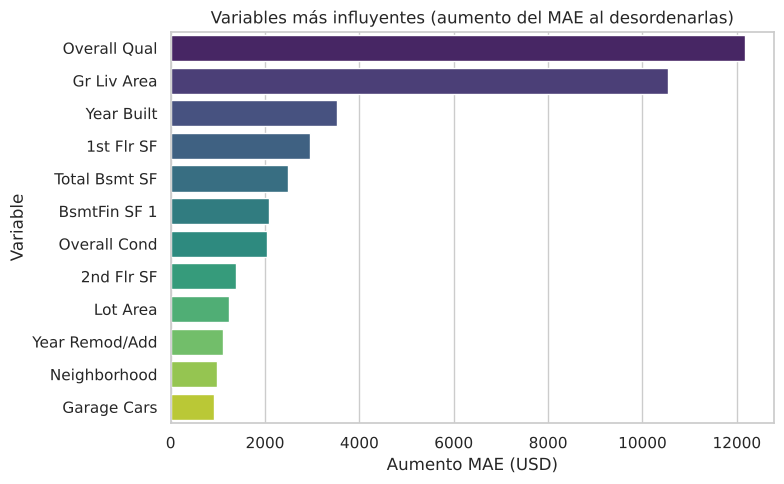

In [ ]:
# Interpretabilidad: importancia por permutación sobre el modelo seleccionado.
# Se mezcla una variable a la vez en el conjunto de prueba y se mide cuánto empeora el MAE;
# a diferencia de la importancia por impureza, funciona con cualquier modelo (incluido el
# Stacking) y no favorece a las variables con muchas categorías.
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_elegido, X_test, y_test, scoring="neg_mean_absolute_error",
                              n_repeats=3, random_state=SEED, n_jobs=-1)
importancia = (pd.DataFrame({"Variable": X_test.columns, "Aumento MAE (USD)": perm.importances_mean})
               .sort_values("Aumento MAE (USD)", ascending=False).head(12))

plt.figure(figsize=(8, 5))
sns.barplot(data=importancia, x="Aumento MAE (USD)", y="Variable", palette="viridis")
plt.title("Variables más influyentes (aumento del MAE al desordenarlas)")
plt.tight_layout()
plt.show()

**Lectura.** Dos variables dominan con claridad: la calidad general (desordenarla sube el MAE en ≈ USD 12 mil) y la superficie habitable (≈ USD 10,5 mil). Les siguen el año de construcción, la superficie del primer piso y la del sótano. Esto coincide con la correlación de la sección 2 y con la lógica del mercado, lo que da confianza en que el modelo aprendió factores de valor reales. Un dato relevante para la sección siguiente: `Neighborhood` tiene un aporte relativamente pequeño (≈ USD 1 mil), aunque otras variables podrían actuar parcialmente como sustitutos de la ubicación.

## 9. Gobernanza, ética y auditoría de sesgo

**Riesgos.**

* **Sesgo geográfico.** Las variables de ubicación (`Neighborhood`) y de antigüedad pueden reproducir diferencias históricas de valoración entre barrios (*redlining*). Un modelo preciso en promedio puede, aun así, subvalorar sistemáticamente ciertas zonas y reforzar esa desigualdad.
* **Cambios no capturados.** El modelo no conoce remodelaciones recientes no declaradas ni cambios macroeconómicos abruptos (por ejemplo, en tasas hipotecarias). Los datos corresponden a ventas de Ames entre 2006 y 2010.
* **Privacidad.** El identificador de parcela (`PID`) y el número de orden se excluyen del modelo. Si se incorporan datos de propietarios o transacciones recientes, hay que revisar la normativa de protección de datos aplicable.

**Auditoría.** En lugar de solo recomendarla, se calcula ahora: para los vecindarios con al menos 15 casas en el conjunto de prueba se mide el **error con signo** (predicho − real, en %). Un valor positivo indica sobrevaloración y uno negativo, subvaloración.

,Viviendas,Precio_medio,Sesgo_medio_pct,Error_abs_medio_pct
Vecindario,,,,
IDOTRR,19,116211.2,-4.8,8.0
Crawfor,16,229226.5,-2.4,8.9
Somerst,37,232898.4,-2.2,5.3
CollgCr,47,196365.3,-0.5,4.3
NWAmes,18,194019.4,-0.2,4.6
Sawyer,25,138600.0,0.2,7.0
SawyerW,28,189794.5,0.8,5.6
OldTown,43,122534.7,1.0,7.4
Gilbert,33,188763.2,1.1,6.3


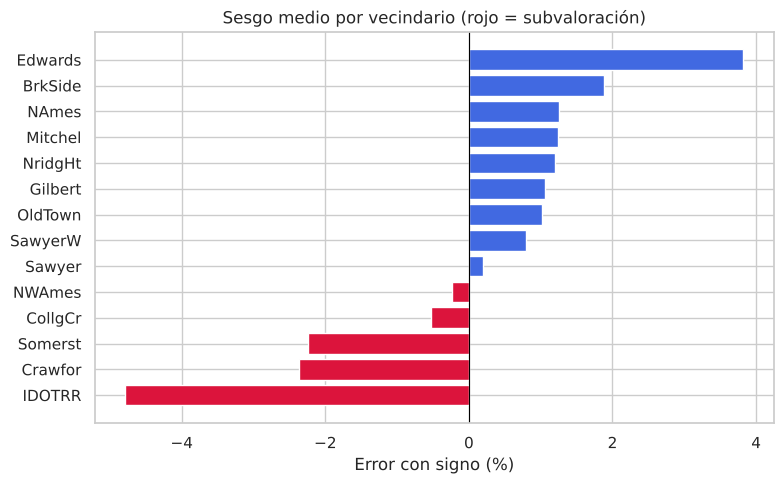

In [ ]:
# Auditoría de sesgo por vecindario: ¿el modelo sobrevalora o subvalora sistemáticamente alguna zona?
# Error con signo (predicho - real) / real: positivo = sobrevaloración, negativo = subvaloración.
auditoria = pd.DataFrame({"Vecindario": X_test["Neighborhood"], "real": y_test, "pred": pred})
auditoria["sesgo_%"] = (auditoria["pred"] - auditoria["real"]) / auditoria["real"] * 100
auditoria["abs_%"] = auditoria["sesgo_%"].abs()
por_barrio = (auditoria.groupby("Vecindario")
              .agg(Viviendas=("real", "size"), Precio_medio=("real", "mean"),
                   Sesgo_medio_pct=("sesgo_%", "mean"), Error_abs_medio_pct=("abs_%", "mean"))
              .query("Viviendas >= 15").sort_values("Sesgo_medio_pct"))   # solo barrios con muestra suficiente
display(por_barrio.round(1))

plt.figure(figsize=(8, 5))
colores = ["crimson" if s < 0 else "royalblue" for s in por_barrio["Sesgo_medio_pct"]]
plt.barh(por_barrio.index, por_barrio["Sesgo_medio_pct"], color=colores)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Sesgo medio por vecindario (rojo = subvaloración)")
plt.xlabel("Error con signo (%)")
plt.tight_layout()
plt.show()

**Lectura de la auditoría.** Con 14 vecindarios de muestra suficiente, el sesgo medio va de ≈ −4,8 % (IDOTRR, el más subvalorado) a ≈ +3,8 % (Edwards, el más sobrevalorado), y el error absoluto medio de ≈ 4,3 % (CollgCr) a ≈ 10,5 % (BrkSide). No aparece un patrón sistemático contra los barrios baratos: IDOTRR, de precio bajo, queda subvalorado, pero Edwards, también de precio bajo, queda sobrevalorado. Aun así, las muestras por vecindario son pequeñas (entre 16 y 91 casas), por lo que estas cifras son **indicativas, no concluyentes**; y el resto de los vecindarios no pudo evaluarse por tener menos de 15 casas en la prueba.

**Controles operativos recomendados:**

* **Supervisión humana (*Human-in-the-Loop*):** el modelo debe operar como apoyo a la decisión del tasador, nunca como aprobador automático único en operaciones de alto monto.
* **Auditoría periódica:** repetir este análisis cada trimestre con datos nuevos, desagregado por vecindario y por segmento, y con más muestra.
* **Umbral de reentrenamiento:** reentrenar cuando el error relativo en producción supere un umbral operativo (por ejemplo, 8 %, frente al 6,2 % actual).

## 10. Conclusiones, limitaciones y próximos pasos

**Conclusiones**

* **Segmentación.** El mercado se divide en 4 perfiles definidos por calidad, superficie y antigüedad, desde viviendas compactas de calidad básica (≈ USD 125 mil) hasta casas premium amplias y modernas (≈ USD 316 mil).
* **Optimización.** Ajustar los hiperparámetros redujo el MAE entre 4 % y 7 % según el modelo, con mayor efecto en los de *boosting*.
* **Ensambles.** El Stacking superó a todos sus componentes y al Voting, tanto en validación cruzada como en prueba, de forma consistente.
* **Generalización.** No hay evidencia de sobreajuste hacia datos nuevos: el error de prueba es menor que el de validación cruzada en todos los modelos.
* **Solución recomendada.** Stacking como modelo de precisión, con MAE ≈ USD 11,4 mil (≈ 6,2 % del precio medio) en datos no vistos, y Ridge como alternativa más interpretable. Calidad general y superficie habitable son los principales impulsores del precio.

**Limitaciones**

* `Lot Frontage` y `Garage Yr Blt` se imputan con la mediana global dentro del Pipeline; una mediana por vecindario, o un indicador de "sin garaje", podría ser más precisa.
* La búsqueda de hiperparámetros tiene un presupuesto limitado (10 a 20 combinaciones por modelo).
* El conjunto de prueba es una sola partición de 586 casas y no se calcularon intervalos de confianza.
* Los datos son de Ames entre 2006 y 2010: el mercado actual puede ser distinto.

**Próximos pasos**

1. **Puesta en producción:** serializar el Pipeline completo (como en la celda siguiente) y exponerlo mediante una API de baja latencia, con alertas sobre el error de predicción. En el portal web, ofrecer a los vendedores una estimación en línea y recomendar a los compradores propiedades del mismo segmento.
2. Repetir la auditoría por vecindario con más datos antes de usar el modelo en operaciones reales.
3. Mejorar el preprocesamiento (imputación por vecindario, indicadores de ausencia, variables derivadas como superficie total o antigüedad al vender) y ampliar el presupuesto de búsqueda.
4. Reentrenar periódicamente y monitorear el MAE con ventas nuevas.

In [ ]:
# Serialización del pipeline completo (preprocesamiento + modelo) para su uso en producción
import joblib

joblib.dump(modelo_elegido, "modelo_tasacion_ames.joblib")
modelo_cargado = joblib.load("modelo_tasacion_ames.joblib")

# Verificación: el modelo cargado debe devolver exactamente las mismas predicciones
assert np.allclose(modelo_cargado.predict(X_test), pred_test[elegido])
muestra = X_test.iloc[[0]]
print(f"Predicción de ejemplo: ${modelo_cargado.predict(muestra)[0]:,.0f} | "
      f"precio real: ${y_test.iloc[0]:,.0f}")

Predicción de ejemplo: $312,500 | precio real: $298,236
